# PPMI MRI time points and data sources

## Assumptions

- Each CSV row counts as one MRI record. Rows are not deduplicated by `PATNO` + `INFODT` or by `EVENT_ID`.
- `MRICMPLT = 1` means completed and `MRICMPLT = 0` means not completed. Missing values are kept as unknown (PPMI guide, p. 38).
- `INFODT` is rounded to month/year for privacy. Two rows for the same participant in the same month may be separate sessions, repeat forms or duplicates. Both are counted.
- All visits are included, not only screening (`EVENT_ID == 'SC'`).
- A completed record does not confirm that a usable image exists.

## 1. Load the data

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

FILE_NAME = "Magnetic_Resonance_Imaging__MRI__03Nov2026.csv"

mri = pd.read_csv(FILE_NAME, dtype={"PATNO": "string", "REC_ID": "string"}, low_memory=False)
required_cols = {"PATNO", "REC_ID", "EVENT_ID", "INFODT", "MRICMPLT"}
assert required_cols.issubset(mri.columns), f"Missing columns: {required_cols - set(mri.columns)}"

print(f"Rows: {len(mri):,} | Participants: {mri['PATNO'].nunique():,} | Columns: {mri.shape[1]}")
display(mri.head())

mri["MRICMPLT"] = pd.to_numeric(mri["MRICMPLT"], errors="coerce")
mri["INFODT_parsed"] = pd.to_datetime(mri["INFODT"], format="%m/%Y", errors="coerce")

Rows: 13,551 | Participants: 6,598 | Columns: 13


,REC_ID,PATNO,EVENT_ID,PAG_NAME,INFODT,OFF_SCHEDULE,MRICMPLT,MRIWDTI,MRIWRSS,MRIRSLT,MRIRSSDF,ORIG_ENTRY,LAST_UPDATE
0,272459801,3000,BL,MRI,02/2011,NaN,1.0,0.0,NaN,2.0,NaN,02/2011,2020-06-25 16:02:19
1,720691201,3000,V12,MRI,NaN,NaN,0.0,NaN,NaN,NaN,NaN,12/2018,2020-06-25 16:02:23
2,278750501,3001,BL,MRI,03/2011,NaN,1.0,0.0,NaN,2.0,NaN,03/2011,2020-06-25 16:04:30
3,281563701,3002,BL,MRI,03/2011,NaN,1.0,0.0,NaN,2.0,NaN,03/2011,2020-04-01 17:33:41
4,287316901,3003,BL,MRI,04/2011,NaN,1.0,0.0,NaN,1.0,NaN,04/2011,2020-06-25 16:06:23


### Time since first visit and first screening

Rows without `INFODT` are dropped first, since they cannot be placed in time. All later sections use only dated rows.

For each record, the number of months since the participant's first visit (earliest `INFODT`) and first screening (earliest `SC` record). `INFODT` only has month and year, so both are whole months. The screening value is empty when the participant has no `SC` record.

In [18]:
undated = mri["INFODT_parsed"].isna()
print(f"Dropping {undated.sum():,} rows without INFODT")
mri = mri[~undated]

Dropping 444 rows without INFODT


In [19]:
def months_between(start, end):
    return ((end.dt.year - start.dt.year) * 12 + (end.dt.month - start.dt.month)).astype("Int64")

first_visit = mri.groupby("PATNO")["INFODT_parsed"].transform("min")
screening_dates = mri[mri["EVENT_ID"] == "SC"].groupby("PATNO")["INFODT_parsed"].min()
first_screening = mri["PATNO"].map(screening_dates)

mri["months_since_first_visit"] = months_between(first_visit, mri["INFODT_parsed"])
mri["months_since_first_screening"] = months_between(first_screening, mri["INFODT_parsed"])

display(mri.loc[mri["PATNO"].isin(["360044", "3107"]),
                ["PATNO", "EVENT_ID", "INFODT", "months_since_first_visit", "months_since_first_screening"]])

,PATNO,EVENT_ID,INFODT,months_since_first_visit,months_since_first_screening
89,3107,BL,04/2011,0,<NA>
90,3107,U02,04/2016,60,<NA>
91,3107,V04,03/2012,11,<NA>
92,3107,V06,05/2013,25,<NA>
93,3107,V10,05/2015,49,<NA>
10245,360044,BL,08/2025,3,3
10246,360044,SC,05/2025,0,0
10247,360044,V04,09/2026,16,16


In [20]:
time_cols = ["months_since_first_visit", "months_since_first_screening"]
mri_timed = mri.dropna(subset=time_cols)

print(f"Rows kept: {len(mri_timed):,} of {len(mri):,} | Participants: {mri_timed['PATNO'].nunique():,}")

Rows kept: 3,607 of 13,107 | Participants: 2,430


## 2. Completion status

In [21]:
completed = mri[mri["MRICMPLT"].eq(1)]
not_completed = mri[mri["MRICMPLT"].eq(0)]
unknown = mri[mri["MRICMPLT"].isna()]
groups = [completed, not_completed, unknown]

status_rows = pd.DataFrame({
    "Status": ["Completed (MRICMPLT = 1)", "Not completed (MRICMPLT = 0)", "Unknown (missing)"],
    "Rows": [len(g) for g in groups],
    "Participants": [g["PATNO"].nunique() for g in groups],
    "Missing INFODT": [g["INFODT"].isna().sum() for g in groups],
})
display(status_rows)

,Status,Rows,Participants,Missing INFODT
0,Completed (MRICMPLT = 1),8902,4912,0
1,Not completed (MRICMPLT = 0),4204,3629,0
2,Unknown (missing),1,1,0


## 3. Records per participant

In [22]:
all_patients = pd.Index(sorted(mri["PATNO"].dropna().unique()), name="PATNO")
patient_counts = pd.DataFrame(index=all_patients)
patient_counts["completed"] = completed.groupby("PATNO").size().reindex(all_patients, fill_value=0)
patient_counts["not_completed"] = not_completed.groupby("PATNO").size().reindex(all_patients, fill_value=0)
patient_counts["unknown"] = unknown.groupby("PATNO").size().reindex(all_patients, fill_value=0)
patient_counts["total_mri_records"] = patient_counts[["completed", "not_completed", "unknown"]].sum(axis=1)
patient_counts = patient_counts.reset_index()

assert patient_counts["completed"].sum() == len(completed)
assert patient_counts["not_completed"].sum() == len(not_completed)
assert patient_counts["unknown"].sum() == len(unknown)
assert patient_counts["total_mri_records"].sum() == len(mri)

both = (patient_counts["completed"].gt(0) & patient_counts["not_completed"].gt(0)).sum()
print(f"Participants with both completed and not-completed records: {both:,}")
display(patient_counts.sort_values(["completed", "not_completed"], ascending=False).head(12))

Participants with both completed and not-completed records: 2,046


,PATNO,completed,not_completed,unknown,total_mri_records
2506,3107,5,0,0,5
4205,42072,5,0,0,5
5047,51330,5,0,0,5
6470,75492,5,0,0,5
210,110219,4,2,0,6
66,101295,4,1,0,5
260,114551,4,1,0,5
462,140671,4,1,0,5
589,150818,4,1,0,5
2845,3327,4,1,0,5


## 4. Distribution of records per participant

Includes participants with zero records of a given status.

,Completed,Not completed
Records per participant,,
0,1583,2866
1,2591,3181
2,998,340
3,981,90
4,338,17
5,4,1


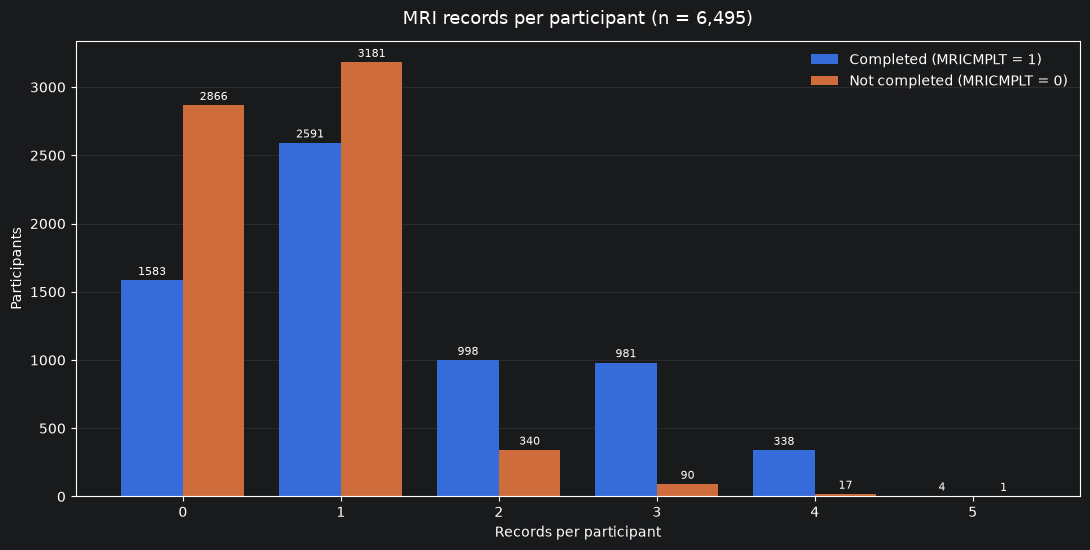

In [23]:
max_n = int(patient_counts[["completed", "not_completed"]].max().max())
counts_axis = pd.Index(range(max_n + 1), name="Records per participant")

dist = pd.DataFrame(index=counts_axis)
dist["Completed"] = patient_counts["completed"].value_counts().reindex(counts_axis, fill_value=0)
dist["Not completed"] = patient_counts["not_completed"].value_counts().reindex(counts_axis, fill_value=0)
display(dist)

fig, ax = plt.subplots(figsize=(11, 5.6))
x = np.arange(len(dist))
w = 0.39
bars1 = ax.bar(x - w / 2, dist["Completed"], width=w, label="Completed (MRICMPLT = 1)")
bars2 = ax.bar(x + w / 2, dist["Not completed"], width=w, label="Not completed (MRICMPLT = 0)")
ax.set_title(f"MRI records per participant (n = {len(patient_counts):,})", fontsize=13, pad=12)
ax.set_xlabel("Records per participant")
ax.set_ylabel("Participants")
ax.set_xticks(x, labels=dist.index)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.16)
ax.set_axisbelow(True)
for bars in (bars1, bars2):
    ax.bar_label(bars, padding=2, fontsize=8)
plt.tight_layout()
plt.show()

### Excluding zero counts

Each panel only counts participants with at least one record of that status, so the two panels cover different groups.

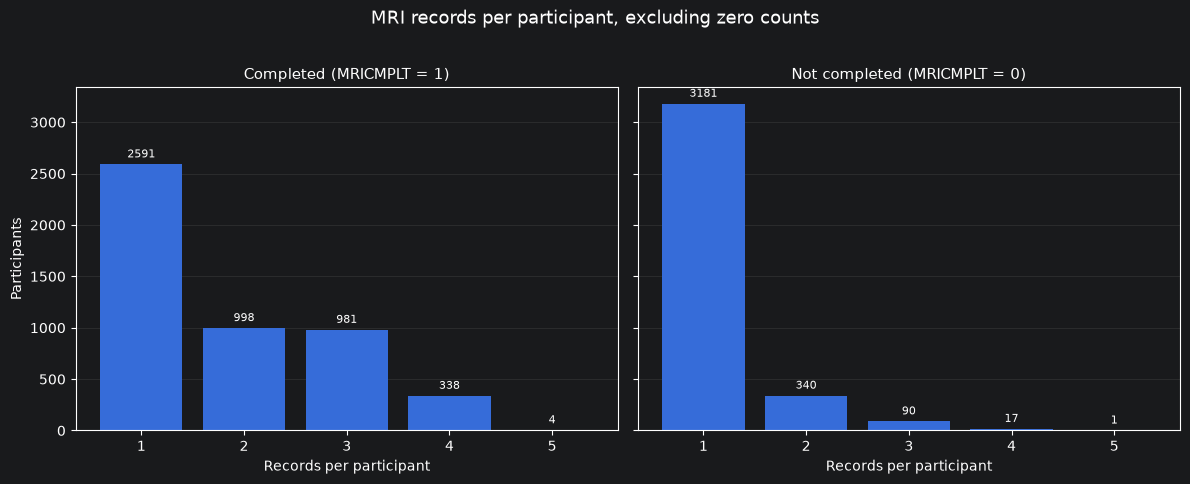

In [24]:
positive_dist = dist.drop(index=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.7), sharey=True)
for ax, column, heading in [
    (ax1, "Completed", "Completed (MRICMPLT = 1)"),
    (ax2, "Not completed", "Not completed (MRICMPLT = 0)"),
]:
    bars = ax.bar(positive_dist.index.astype(str), positive_dist[column])
    ax.set_title(heading, fontsize=11)
    ax.set_xlabel("Records per participant")
    ax.grid(axis="y", alpha=0.16)
    ax.set_axisbelow(True)
    ax.bar_label(bars, padding=3, fontsize=8)
ax1.set_ylabel("Participants")
fig.suptitle("MRI records per participant, excluding zero counts", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 5. Completed time points per participant

Completed records are listed by date as `EVENT_ID @ INFODT`. `SC` is screening, `BL` is baseline and `V` codes are follow-up visits.

In [25]:
completed_ordered = completed.sort_values(["PATNO", "INFODT_parsed", "REC_ID"], na_position="last")
labels = completed_ordered["EVENT_ID"].fillna("unknown") + " @ " + completed_ordered["INFODT"].fillna("unknown")
timepoints = labels.groupby(completed_ordered["PATNO"], sort=False).agg(" | ".join).rename("completed_timepoints")

patient_timepoints = patient_counts.join(timepoints, on="PATNO")
patient_timepoints["completed_timepoints"] = patient_timepoints["completed_timepoints"].fillna("")
display(patient_timepoints.sort_values(["completed", "PATNO"], ascending=[False, True]).head(15))

,PATNO,completed,not_completed,unknown,total_mri_records,completed_timepoints
2506,3107,5,0,0,5,BL @ 04/2011 | V04 @ 03/2012 | V06 @ 05/2013 |...
4205,42072,5,0,0,5,BL @ 08/2015 | V04 @ 08/2016 | V06 @ 08/2017 |...
5047,51330,5,0,0,5,BL @ 03/2015 | V04 @ 03/2016 | V06 @ 04/2017 |...
6470,75492,5,0,0,5,BL @ 11/2018 | V06 @ 04/2021 | V10 @ 03/2023 |...
4,100007,4,0,0,4,BL @ 12/2020 | V04 @ 01/2022 | V06 @ 03/2023 |...
5,100012,4,0,0,4,BL @ 03/2021 | V04 @ 02/2022 | V06 @ 01/2023 |...
6,100017,4,0,0,4,BL @ 12/2020 | V04 @ 12/2021 | V06 @ 01/2023 |...
10,100122,4,0,0,4,BL @ 10/2022 | V04 @ 11/2023 | V06 @ 10/2024 |...
11,100232,4,0,0,4,BL @ 06/2022 | V04 @ 06/2023 | V06 @ 06/2024 |...
12,100250,4,0,0,4,BL @ 11/2022 | V04 @ 11/2023 | V06 @ 01/2025 |...


## 6. Where to find demographic and clinical data

Each column is a variable, and the cell below it names the PPMI dataset(s) that contain it. The table lists sources, not participant data.

In [26]:
feature_source_map = {
    "Patient ID (PATNO)": "MRI CSV; Participant Status; most PPMI Clinical tables",
    "Birth month/year (BIRTHDT)": "Demographics",
    "Sex (SEX)": "Demographics",
    "Race and ethnicity": "Demographics",
    "Handedness": "Demographics",
    "Gender identity": "Demographics / Curated Data Cut",
    "Years of education": "Socio-Economics",
    "Age at study enrollment (ENROLL_AGE)": "Participant Status",
    "Age at visit": "Age at Visit",
    "Enrollment cohort (COHORT_DEFINITION)": "Participant Status",
    "Enrollment status (ENROLL_STATUS)": "Participant Status",
    "Genetic risk subgroup": "Participant Status; Participant Genetic Status",
    "Family history of PD": "Family History",
    "PD diagnosis and diagnosis date": "PD Diagnosis History; Primary Clinical Diagnosis",
    "Age at PD diagnosis / symptom onset": "PD Diagnosis History; Curated Data Cut",
    "Motor examination severity (MDS-UPDRS III)": "MDS-UPDRS Part III",
    "Hoehn and Yahr stage": "MDS-UPDRS Part III",
    "Non-motor symptoms (MDS-UPDRS I)": "MDS-UPDRS Part I; Part I Patient Questionnaire",
    "Motor activities of daily living (MDS-UPDRS II)": "MDS-UPDRS Part II Patient Questionnaire",
    "Motor complications (MDS-UPDRS IV)": "MDS-UPDRS Part IV Motor Complications",
    "Cognitive status (MoCA)": "Montreal Cognitive Assessment (MoCA)",
    "Other neuropsychological tests": "Non-motor Assessments / Neuropsychological Tests",
    "Smell identification score (UPSIT)": "University of Pennsylvania Smell Identification Test (UPSIT)",
    "Autonomic symptoms (SCOPA-AUT)": "SCOPA-AUT",
    "Depression / anxiety measures": "Non-motor Assessments / Neurobehavioral Tests",
    "Sleep / RBD assessments": "Non-motor Assessments / Sleep Disorder Tests",
    "Parkinson's medication / LEDD": "LEDD Concomitant Medication Log",
    "Other medication": "Concomitant Medication Log",
    "Blood pressure / height / weight": "Vital Signs",
    "Comorbidities": "Medical Conditions Log",
    "Tremor / rigidity / freezing / falls": "Features of Parkinsonism; Determination of Freezing and Falls",
    "DaTscan imaging assessment": "DaTscan Analysis; DaTscan Visual Interpretation Results",
    "Disease biomarkers / NSD stage": "Curated Data Cut; relevant biospecimen / DaTscan test files",
}

sources = pd.DataFrame([feature_source_map], index=["PPMI source dataset(s)"])
display(HTML(f'<div style="overflow-x:auto">{sources.to_html()}</div>'))

,Patient ID (PATNO),Birth month/year (BIRTHDT),Sex (SEX),Race and ethnicity,Handedness,Gender identity,Years of education,Age at study enrollment (ENROLL_AGE),Age at visit,Enrollment cohort (COHORT_DEFINITION),Enrollment status (ENROLL_STATUS),Genetic risk subgroup,Family history of PD,PD diagnosis and diagnosis date,Age at PD diagnosis / symptom onset,Motor examination severity (MDS-UPDRS III),Hoehn and Yahr stage,Non-motor symptoms (MDS-UPDRS I),Motor activities of daily living (MDS-UPDRS II),Motor complications (MDS-UPDRS IV),Cognitive status (MoCA),Other neuropsychological tests,Smell identification score (UPSIT),Autonomic symptoms (SCOPA-AUT),Depression / anxiety measures,Sleep / RBD assessments,Parkinson's medication / LEDD,Other medication,Blood pressure / height / weight,Comorbidities,Tremor / rigidity / freezing / falls,DaTscan imaging assessment,Disease biomarkers / NSD stage
PPMI source dataset(s),MRI CSV; Participant Status; most PPMI Clinical tables,Demographics,Demographics,Demographics,Demographics,Demographics / Curated Data Cut,Socio-Economics,Participant Status,Age at Visit,Participant Status,Participant Status,Participant Status; Participant Genetic Status,Family History,PD Diagnosis History; Primary Clinical Diagnosis,PD Diagnosis History; Curated Data Cut,MDS-UPDRS Part III,MDS-UPDRS Part III,MDS-UPDRS Part I; Part I Patient Questionnaire,MDS-UPDRS Part II Patient Questionnaire,MDS-UPDRS Part IV Motor Complications,Montreal Cognitive Assessment (MoCA),Non-motor Assessments / Neuropsychological Tests,University of Pennsylvania Smell Identification Test (UPSIT),SCOPA-AUT,Non-motor Assessments / Neurobehavioral Tests,Non-motor Assessments / Sleep Disorder Tests,LEDD Concomitant Medication Log,Concomitant Medication Log,Vital Signs,Medical Conditions Log,Features of Parkinsonism; Determination of Freezing and Falls,DaTscan Analysis; DaTscan Visual Interpretation Results,Curated Data Cut; relevant biospecimen / DaTscan test files
